# Importing and exploring the dataset

In [201]:
# Importing the libraries and the module we have set up
import customer_scoring as cs
import pandas as pd

#reading the file 
customer_segmentation_data = pd.read_csv("customer_segmentation_data.csv")


#displaying the first 5 rows
customer_segmentation_data.head()

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount
0,1,38,Female,99342,90,3,24,Groceries,113.53
1,2,21,Female,78852,60,2,42,Sports,41.93
2,3,60,Female,126573,30,2,28,Clothing,424.36
3,4,40,Other,47099,74,9,5,Home & Garden,991.93
4,5,65,Female,140621,21,3,25,Electronics,347.08


In [202]:
#displaying last 5 rows
customer_segmentation_data.tail()

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount
995,996,57,Male,112170,57,6,1,Clothing,313.64
996,997,23,Other,65337,76,10,23,Groceries,632.83
997,998,23,Male,113097,40,5,42,Sports,75.09
998,999,22,Female,113695,63,7,44,Electronics,505.16
999,1000,36,Female,90420,7,2,31,Groceries,669.26


In [203]:
#displaying numbers of rows and columns
print("Number of rows:", customer_segmentation_data.shape[0])
print("Number of columns:", customer_segmentation_data.shape[1])

Number of rows: 1000
Number of columns: 9


In [204]:
# Inspect column names and data types.
customer_segmentation_data.columns
customer_segmentation_data.dtypes

id                        int64
age                       int64
gender                      str
income                    int64
spending_score            int64
membership_years          int64
purchase_frequency        int64
preferred_category          str
last_purchase_amount    float64
dtype: object

In [205]:
#Separate the numerical/categorical/identifier variables.
numerical=[]
categorical=[]
idetifier=[]
for elt in customer_segmentation_data.dtypes.items():
  if elt[0]== "id":
     idetifier.append(elt[0])
  elif elt[1]== "int64" or elt[1]=="float64":
    numerical.append(elt[0])
  else:
    categorical.append(elt[0])


print(f"The identifier variables are  {idetifier}.")
print(f"The numerical variables are {numerical}.")
print(f"The categorical variables are {categorical}.")


The identifier variables are  ['id'].
The numerical variables are ['age', 'income', 'spending_score', 'membership_years', 'purchase_frequency', 'last_purchase_amount'].
The categorical variables are ['gender', 'preferred_category'].


In [206]:
# Calculating the unique number of ids
customer_segmentation_data["id"].nunique()

1000

# Data cleaning

In [207]:
#checking for missing values
missing_values = customer_segmentation_data.isna().sum()
   
missing_values
#Since the missing count is 0 for all the values, all the fields are complete

id                      0
age                     0
gender                  0
income                  0
spending_score          0
membership_years        0
purchase_frequency      0
preferred_category      0
last_purchase_amount    0
dtype: int64

In [208]:
#  Check for exact duplicate rows
duplicated_values = customer_segmentation_data.duplicated()
customer_segmentation_data[customer_segmentation_data.duplicated()]
#Since the function is not displaying any values it means we ahve no duplications

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount


In [209]:
#inspect min/max for numerical variables
customer_segmentation_data[numerical].describe().round(2)

,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,43.78,88500.80,50.68,5.47,26.60,492.35
std,15.04,34230.77,28.96,2.86,14.24,295.74
min,18.00,30004.00,1.00,1.00,1.00,10.40
25%,30.00,57911.75,26.00,3.00,15.00,218.76
50%,45.00,87845.50,50.00,5.00,27.00,491.60
75%,57.00,116110.25,76.00,8.00,39.00,747.17
max,69.00,149973.00,100.00,10.00,50.00,999.74


In [210]:
#calculate the mode
mode_columns = [
    "age",
    "spending_score",
    "membership_years",
    "purchase_frequency"
]

for column in mode_columns:
    print(column, ":", customer_segmentation_data[column].mode().tolist())

age : [47]
spending_score : [70]
membership_years : [5]
purchase_frequency : [28]


In [211]:
#checking for any spelling errors/inconsistencies in categorical variables
for column in categorical:
  print(f"Unique values in {column} :")
  for unique_value in customer_segmentation_data[column].unique():
    print(unique_value)
  print("\n")
# since the unique values show no repetiotion or missspelling, we can be sure that the categorical data is also clean

Unique values in gender :
Female
Other
Male


Unique values in preferred_category :
Groceries
Sports
Clothing
Home & Garden
Electronics




# Data Preparation and Feature Engineering

In [212]:
#Adding a new column for age groups
customer_segmentation_data["age_group"] = pd.cut(
    customer_segmentation_data["age"],
    bins=[17, 25, 35, 45, 60, float("inf")],
    labels=["18-25", "26-35", "36-45", "46-60", "61+"]
)
customer_segmentation_data.head()

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount,age_group
0,1,38,Female,99342,90,3,24,Groceries,113.53,36-45
1,2,21,Female,78852,60,2,42,Sports,41.93,18-25
2,3,60,Female,126573,30,2,28,Clothing,424.36,46-60
3,4,40,Other,47099,74,9,5,Home & Garden,991.93,36-45
4,5,65,Female,140621,21,3,25,Electronics,347.08,61+


In [213]:
#Adding a new column for income
customer_segmentation_data["income_group"]=pd.cut(
    customer_segmentation_data["income"],
    bins = [0,60000,90000,120000,float("inf")],
    labels=["Low income","Lower-middle income","Upper-middle income","High income"]
)
customer_segmentation_data.head()

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount,age_group,income_group
0,1,38,Female,99342,90,3,24,Groceries,113.53,36-45,Upper-middle income
1,2,21,Female,78852,60,2,42,Sports,41.93,18-25,Lower-middle income
2,3,60,Female,126573,30,2,28,Clothing,424.36,46-60,High income
3,4,40,Other,47099,74,9,5,Home & Garden,991.93,36-45,Low income
4,5,65,Female,140621,21,3,25,Electronics,347.08,61+,High income


In [214]:
#Adding a new column for membership years
customer_segmentation_data["membership_group"] = pd.cut(
    customer_segmentation_data["membership_years"],
    bins=[0, 1, 3, 5, float("inf")],
    labels=["New member", "Developping member", "Established member", "Longterm member"]
)
customer_segmentation_data.head()

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount,age_group,income_group,membership_group
0,1,38,Female,99342,90,3,24,Groceries,113.53,36-45,Upper-middle income,Developping member
1,2,21,Female,78852,60,2,42,Sports,41.93,18-25,Lower-middle income,Developping member
2,3,60,Female,126573,30,2,28,Clothing,424.36,46-60,High income,Developping member
3,4,40,Other,47099,74,9,5,Home & Garden,991.93,36-45,Low income,Longterm member
4,5,65,Female,140621,21,3,25,Electronics,347.08,61+,High income,Developping member


In [215]:
#Adding a new column for purchase frequency
customer_segmentation_data["purchase_frequency_group"]=pd.cut(
    customer_segmentation_data["purchase_frequency"],
    bins = [0,15,27,39,float("inf")],
    labels=["Low frequency","Lower-middle frequency","Upper-middle frequency","High frequency"]
)
customer_segmentation_data.head()

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount,age_group,income_group,membership_group,purchase_frequency_group
0,1,38,Female,99342,90,3,24,Groceries,113.53,36-45,Upper-middle income,Developping member,Lower-middle frequency
1,2,21,Female,78852,60,2,42,Sports,41.93,18-25,Lower-middle income,Developping member,High frequency
2,3,60,Female,126573,30,2,28,Clothing,424.36,46-60,High income,Developping member,Upper-middle frequency
3,4,40,Other,47099,74,9,5,Home & Garden,991.93,36-45,Low income,Longterm member,Low frequency
4,5,65,Female,140621,21,3,25,Electronics,347.08,61+,High income,Developping member,Lower-middle frequency


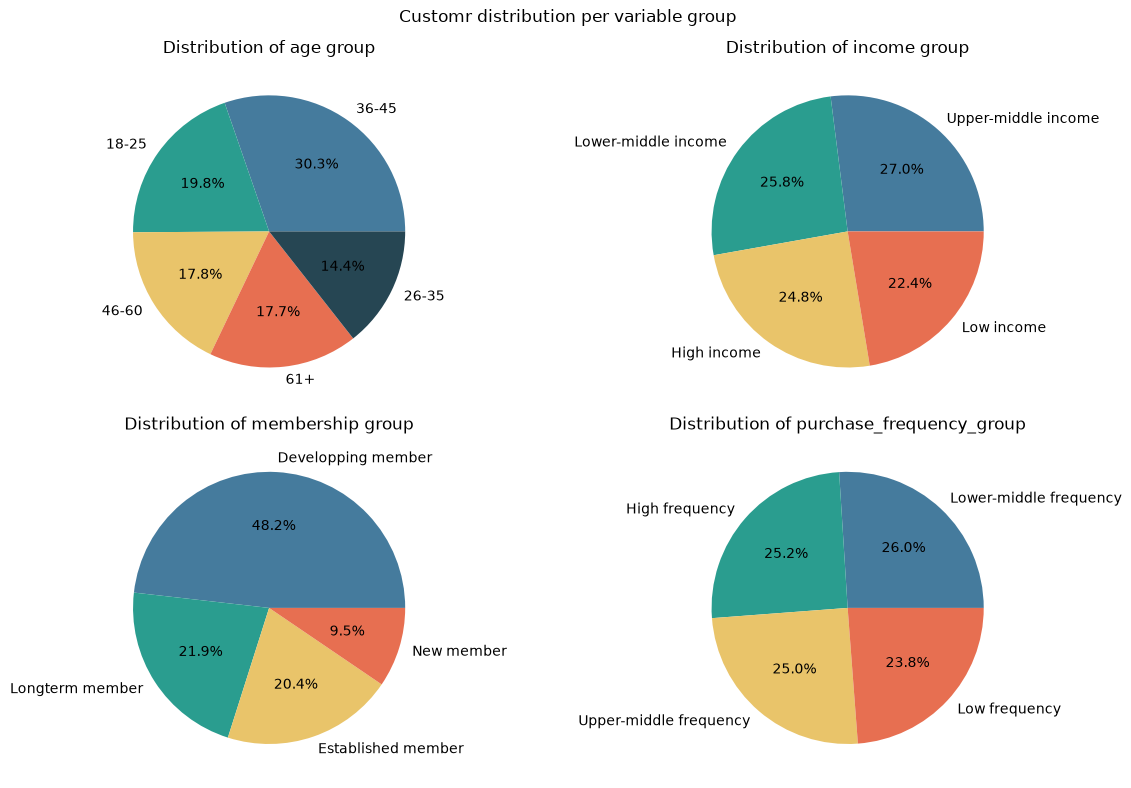

In [216]:
# The pie charts for distributions of newly added columns

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8)) # adding in more space


# age_group
plt.subplot(2,2,1)
plt.pie(customer_segmentation_data["age_group"].value_counts(), labels=customer_segmentation_data["age_group"].unique(), autopct='%1.1f%%',colors=["#457B9D", "#2A9D8F", "#E9C46A","#E76F51","#264653"] )
plt.title("Distribution of age group")

# income_group
plt.subplot(2,2,2)
plt.pie(customer_segmentation_data["income_group"].value_counts(), labels=customer_segmentation_data["income_group"].unique(), autopct='%1.1f%%',colors=["#457B9D", "#2A9D8F", "#E9C46A","#E76F51"] )
plt.title("Distribution of income group")


# membership_group
plt.subplot(2,2,3)
plt.pie(customer_segmentation_data["membership_group"].value_counts(), labels=customer_segmentation_data["membership_group"].unique(), autopct='%1.1f%%',colors=["#457B9D", "#2A9D8F", "#E9C46A","#E76F51"] )
plt.title("Distribution of membership group")


# purchase frequency group
plt.subplot(2,2,4)
plt.pie(customer_segmentation_data["purchase_frequency_group"].value_counts(), labels=customer_segmentation_data["purchase_frequency_group"].unique(), autopct='%1.1f%%',colors=["#457B9D", "#2A9D8F", "#E9C46A","#E76F51"] )
plt.title("Distribution of purchase_frequency_group")


plt.suptitle("Customr distribution per variable group")
plt.tight_layout()
plt.show()

In [217]:
#Comparing mean and median
comparison = pd.DataFrame({
    "Mean": customer_segmentation_data[numerical].mean(),
    "Median": customer_segmentation_data[numerical].median()
})

comparison["Difference"] = comparison["Mean"] - comparison["Median"]

comparison.round(2)
#The means and medians are relatively close across the numerical variables. This comparison does not indicate pronounced skewness. 
#Histograms will help assess the shapes of the distributions more fully.


,Mean,Median,Difference
age,43.78,45.0,-1.22
income,88500.80,87845.5,655.30
spending_score,50.68,50.0,0.69
membership_years,5.47,5.0,0.47
purchase_frequency,26.60,27.0,-0.40
last_purchase_amount,492.35,491.6,0.75


# KPI Summary

In [218]:
#Create a KPI summary table.
KPI_summary = pd.DataFrame({
    'KPI': [
        'Total number of customers',
        'Average of customer\'s age',
        'Maximum of customer\'s age',
        'Minimum of customer\'s age',
        'Average of customer\'s income',
        'Maximum of customer\'s income',
        'Minimum of customer\'income',
        'Average of spending score',
        'Maximum of spending score',
        'Minimum of spending score',
        'Average of membership duration',
        'Maximum  of membership duration',
        'Minimum of membership duration',
        'Average of purchase frequency',
        'Maximum  of purchase frequency',
        'Minimum of purchase frequency',
        'Average of last purchase amount',
        'Maximum  of last purchase amount',
        'Minimum of last purchase amount',

    ],
    'Value': [
        customer_segmentation_data['id'].nunique(),
        customer_segmentation_data['age'].mean(),
        customer_segmentation_data['age'].max(),
        customer_segmentation_data['age'].min(),
        customer_segmentation_data['income'].mean(),
        customer_segmentation_data['income'].max(),
        customer_segmentation_data['income'].min(),
        customer_segmentation_data['spending_score'].mean(),
        customer_segmentation_data['spending_score'].max(),
        customer_segmentation_data['spending_score'].min(),
        customer_segmentation_data['membership_years'].mean(),
        customer_segmentation_data['membership_years'].max(),
        customer_segmentation_data['membership_years'].min(),
        customer_segmentation_data['purchase_frequency'].mean(),
        customer_segmentation_data['purchase_frequency'].max(),
        customer_segmentation_data['purchase_frequency'].min(),
        customer_segmentation_data['last_purchase_amount'].mean(),
        customer_segmentation_data['last_purchase_amount'].max(),
        customer_segmentation_data['last_purchase_amount'].min(),
    ]
})
KPI_summary.style \
    .set_properties(
        subset=['KPI', 'Value'],
        **{'text-align': 'left'}
    ) \
    .set_table_styles([
        {'selector': 'th',
         'props': [('text-align', 'left')]}
    ]) \
    .format({
        'Value': '{:.2f}'
    })

,KPI,Value
0,Total number of customers,1000.00
1,Average of customer's age,43.78
2,Maximum of customer's age,69.00
3,Minimum of customer's age,18.00
4,Average of customer's income,88500.80
5,Maximum of customer's income,149973.00
6,Minimum of customer'income,30004.00
7,Average of spending score,50.69
8,Maximum of spending score,100.00
9,Minimum of spending score,1.00


# Customer distributions

In [219]:
# Calculate the distribution of customers across preferred product categories.
list=[]
list.append(customer_segmentation_data['preferred_category'].value_counts()/customer_segmentation_data.shape[0]*100)
customer_segmentation_data['preferred_category'].value_counts()/customer_segmentation_data.shape[0]*100
# most prefereed : electronics
# lest preferred : clothing

preferred_category
Electronics      21.5
Sports           21.0
Home & Garden    20.6
Groceries        19.9
Clothing         17.0
Name: count, dtype: float64

In [220]:
#  Compare purchase frequency across membership-duration groups.
customer_segmentation_data.groupby('membership_group').groups # goup the customers by the membership_group
customer_segmentation_data.groupby('membership_group')['purchase_frequency'].mean().round(2)

membership_group
New member            25.60
Developping member    25.54
Established member    26.21
Longterm member       27.41
Name: purchase_frequency, dtype: float64

In [221]:
# # Further investigate spending behaviour across membership groups
# by examining the number of customers, mean, median, standard deviation,
# minimum and maximum spending scores in each group.
customer_segmentation_data.groupby('membership_group')['spending_score'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

,count,mean,median,std,min,max
membership_group,,,,,,
New member,95,49.93,53.0,30.51,1,100
Developping member,204,50.49,53.0,28.32,1,100
Established member,219,50.14,47.0,28.02,1,100
Longterm member,482,51.17,50.5,29.40,1,100


In [222]:
#Compare preferred categories across age and income groups.
# comparing age
age_preffered_category = pd.crosstab(
    customer_segmentation_data["age_group"],
    customer_segmentation_data["preferred_category"],
    normalize="index"
).mul(100).round(1)

display(
    age_preffered_category.style.format("{:.2f}%"
    ).highlight_max(axis=1, color="lightgreen")
)


preferred_category,Clothing,Electronics,Groceries,Home & Garden,Sports
age_group,,,,,
18-25,16.70%,25.70%,18.80%,20.10%,18.80%
26-35,15.20%,23.20%,18.20%,20.70%,22.70%
36-45,14.60%,18.00%,27.00%,20.20%,20.20%
46-60,17.80%,21.50%,18.80%,22.40%,19.50%
61+,20.30%,19.80%,17.50%,18.10%,24.30%


In [223]:
#comparing income
income_preffered_category = pd.crosstab(
    customer_segmentation_data["income_group"],
    customer_segmentation_data["preferred_category"],
    normalize="index"
).mul(100).round(1)

display(
    income_preffered_category.style.format("{:.2f}%"
    ).highlight_max(axis=1, color="lightgreen")
)


preferred_category,Clothing,Electronics,Groceries,Home & Garden,Sports
income_group,,,,,
Low income,14.10%,22.60%,22.60%,20.00%,20.70%
Lower-middle income,20.20%,18.50%,16.90%,21.40%,23.00%
Upper-middle income,17.10%,20.90%,19.80%,20.50%,21.70%
High income,17.00%,24.10%,20.10%,20.50%,18.30%


# Data visualization

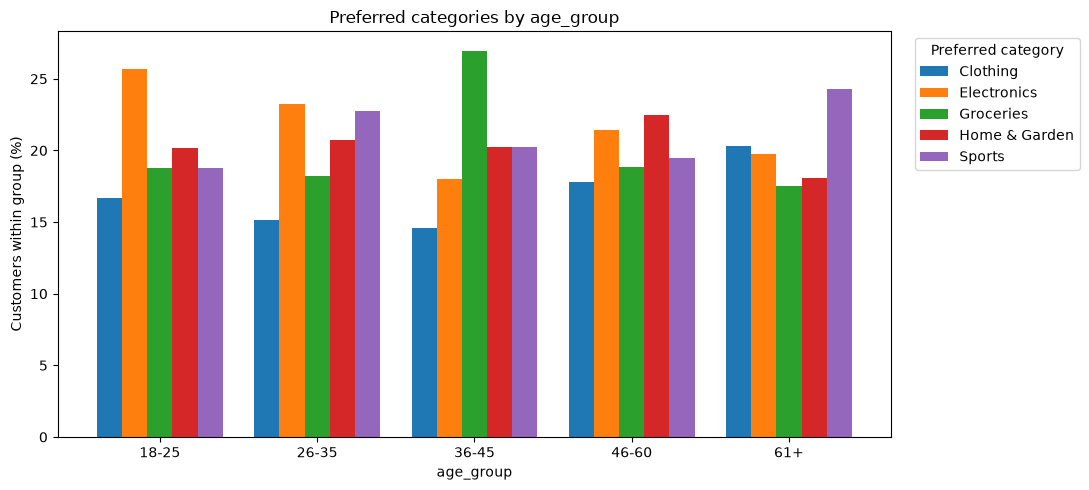

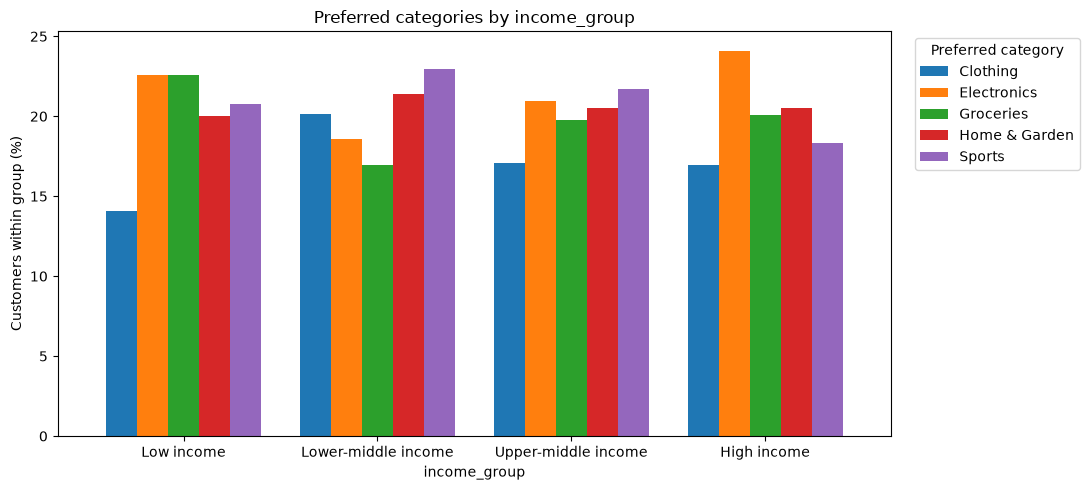

In [224]:
# Creating bar charts and grouped comparisons.
import pandas as pd
import matplotlib.pyplot as plt

for group in ["age_group", "income_group"]:

    percentages = pd.crosstab(
        customer_segmentation_data[group],
        customer_segmentation_data["preferred_category"],
        normalize="index"
    ).mul(100)

    percentages.plot(
        kind="bar",
        figsize=(11, 5),
        width=0.8
    )

    plt.title(f"Preferred categories by {group}")
    plt.xlabel(group)
    plt.ylabel("Customers within group (%)")
    plt.xticks(rotation=0)
    plt.legend(title="Preferred category", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()


# Correlation

In [225]:
# Correlation between numerical variables
correlation = customer_segmentation_data[numerical].corr()
display(correlation)

,age,income,spending_score,membership_years,purchase_frequency,last_purchase_amount
age,1.000000,-0.000688,0.017707,-0.003431,-0.030137,0.061599
income,-0.000688,1.000000,0.000020,-0.035783,0.000533,-0.054006
spending_score,0.017707,0.000020,1.000000,0.026726,0.006708,-0.014475
membership_years,-0.003431,-0.035783,0.026726,1.000000,0.069532,-0.014135
purchase_frequency,-0.030137,0.000533,0.006708,0.069532,1.000000,0.024400
last_purchase_amount,0.061599,-0.054006,-0.014475,-0.014135,0.024400,1.000000


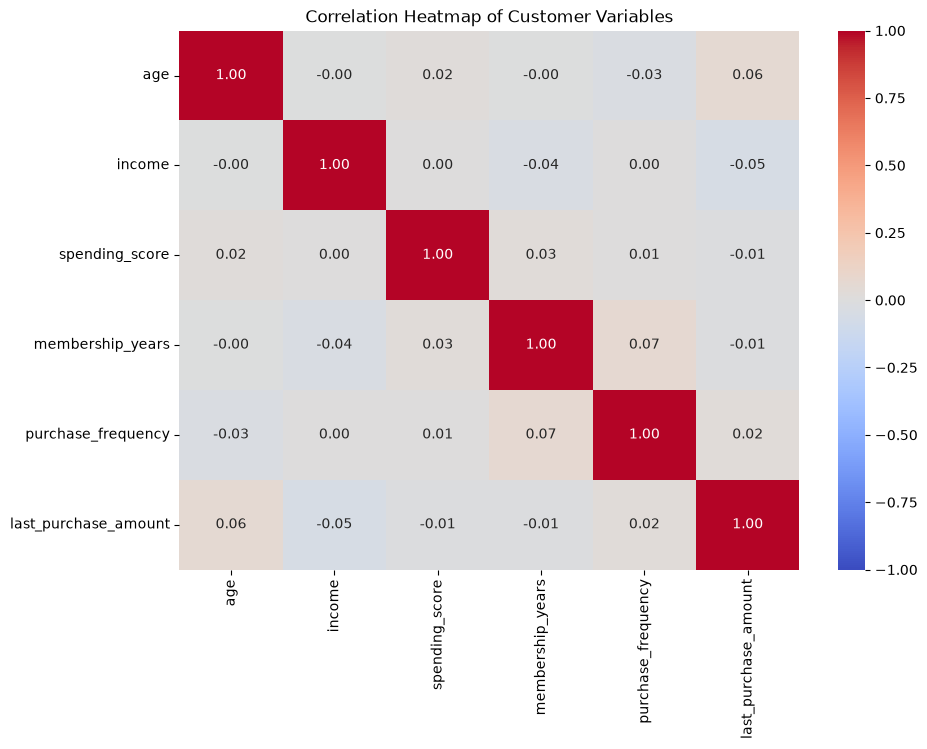

In [226]:
# Correlation visualization by a heatmap
import matplotlib.pyplot as plt
import seaborn as sns


# Heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Customer Variables")
plt.show()

# Customer scoring

Calculating CVS - customer value score

In [227]:
#CVS is the average of three normalised indicators:
#- Purchase frequency.
#- Spending score.
#- Last purchase amount.
#defining cvs_columns:
cvs_columns = [
    "purchase_frequency",
    "spending_score",
    "last_purchase_amount"
]
# Creating three normalized columns using the function from customer_scoring.py:
for column in cvs_columns:
    customer_segmentation_data[column + "_norm"] = cs.normalize(
        customer_segmentation_data[column],
        customer_segmentation_data[column].min(),
        customer_segmentation_data[column].max()
    )

# Viewing the results for the first five customers:
customer_segmentation_data[
    [column + "_norm" for column in cvs_columns]
].head()

,purchase_frequency_norm,spending_score_norm,last_purchase_amount_norm
0,46.938776,89.898990,10.424121
1,83.673469,59.595960,3.186973
2,55.102041,29.292929,41.842036
3,8.163265,73.737374,99.210585
4,48.979592,20.202020,34.030768


In [228]:
# Applying the function from customer_scoring.py to calculate CVS for each customer:
customer_segmentation_data["CVS"] = cs.calculate_cvs(
    customer_segmentation_data["purchase_frequency_norm"],
    customer_segmentation_data["spending_score_norm"],
    customer_segmentation_data["last_purchase_amount_norm"]
)

# Viewing the results for the first five customers:
display(
    customer_segmentation_data[
        [
            "purchase_frequency_norm",
            "spending_score_norm",
            "last_purchase_amount_norm",
            "CVS"
        ]
    ].head()
)

,purchase_frequency_norm,spending_score_norm,last_purchase_amount_norm,CVS
0,46.938776,89.898990,10.424121,49.087296
1,83.673469,59.595960,3.186973,48.818801
2,55.102041,29.292929,41.842036,42.079002
3,8.163265,73.737374,99.210585,60.370408
4,48.979592,20.202020,34.030768,34.404127


In [229]:
#checking the CVS for errors before creating customers segments
customer_segmentation_data["CVS"].isna().sum()

np.int64(0)

In [230]:
# Creating the segments using the function from customer_scoring.py:

# Assigning a CVS segment to each customer:
customer_segmentation_data["CVS_group"] = [
    cs.assign_segment(cvs)
    for cvs in customer_segmentation_data["CVS"]
]  # List comprehension

# Viewing the results:
customer_segmentation_data.head()

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount,age_group,income_group,membership_group,purchase_frequency_group,purchase_frequency_norm,spending_score_norm,last_purchase_amount_norm,CVS,CVS_group
0,1,38,Female,99342,90,3,24,Groceries,113.53,36-45,Upper-middle income,Developping member,Lower-middle frequency,46.938776,89.898990,10.424121,49.087296,Medium CVS
1,2,21,Female,78852,60,2,42,Sports,41.93,18-25,Lower-middle income,Developping member,High frequency,83.673469,59.595960,3.186973,48.818801,Medium CVS
2,3,60,Female,126573,30,2,28,Clothing,424.36,46-60,High income,Developping member,Upper-middle frequency,55.102041,29.292929,41.842036,42.079002,Medium CVS
3,4,40,Other,47099,74,9,5,Home & Garden,991.93,36-45,Low income,Longterm member,Low frequency,8.163265,73.737374,99.210585,60.370408,Medium CVS
4,5,65,Female,140621,21,3,25,Electronics,347.08,61+,High income,Developping member,Lower-middle frequency,48.979592,20.202020,34.030768,34.404127,Low CVS


In [231]:
# checking the numbers in each segments
customer_segmentation_data["CVS_group"].value_counts(
    sort=False, dropna=False
)

CVS_group
Medium CVS    500
Low CVS       250
High CVS      250
Name: count, dtype: int64

In [232]:
#let’s focus on Medium CVS because it’s the largest group: 500 customers (50% of the total number of customers)
# the question becomes: What characterises medium-CVS customers, and which purchasing indicators offer opportunities for improvement?
#We’ll use Higher CVS as a reference and examine differences in income, age, membership duration and preferences.
customer_segmentation_data.groupby(
    "CVS_group", observed=True
)[[
    "purchase_frequency_norm",
    "spending_score_norm",
    "last_purchase_amount_norm"
]].mean().round(3)
#This gives one row per segment and the average of each indicator, on the same 0–1 scale.
#For example, if Medium CVS has a much lower purchase-frequency average than Higher CVS,
# we’ll investigate who buys less often within the Medium segment—their age, income and membership duration...

,purchase_frequency_norm,spending_score_norm,last_purchase_amount_norm
CVS_group,,,
High CVS,72.547,71.531,72.056
Low CVS,30.033,29.018,26.170
Medium CVS,53.184,50.099,48.315


In [233]:
#The largest normalised gap is in last purchase amount, but the gaps are fairly similar.
# There isn’t one clearly dominant weakness.
#These differences are partly expected: we created the CVS groups using these same indicators.
# They describe the segments; they don’t explain their underlying behaviour.

#Comparing age, income and membership duration:
customer_segmentation_data.groupby(
    "CVS_group", observed=True
)[["age", "income", "membership_years"]].agg(
    ["mean", "median"]
).round(2)

age           income          membership_years       
             mean median      mean   median             mean median
CVS_group                                                          
High CVS    44.49   45.0  86947.65  86818.0             5.80    6.0
Low CVS     43.72   45.0  89414.60  90622.0             5.51    5.0
Medium CVS  43.46   45.0  88820.47  86367.5             5.28    5.0

In [234]:
#average per preferred_category
customer_segmentation_data.groupby("preferred_category")["CVS"].mean().round(2)

preferred_category
Clothing         50.10
Electronics      50.28
Groceries        50.79
Home & Garden    50.21
Sports           50.49
Name: CVS, dtype: float64

In [235]:
#Our idea is to use customer segmentation to develop targeted retention recommendations.
#We combine each customer’s CVS level—Lower, Medium or Higher—with their preferred product category.
#The CVS level helps us choose the type of action, while product preference helps us make it relevant.
#For example, we could test category-specific offers for Lower-CVS customers, loyalty benefits for Medium-CVS customers,
#and early access for Higher-CVS customers.
#The objective is to maintain engagement and encourage repeat purchases, rather than simply move everyone into a higher score category.
#These are proposed actions to test: CVS measures relative commercial activity, not the risk of losing a customer.

In [236]:
#Medium- and Higher-CVS customers have similar age and income profiles. Membership duration shows a modest difference.
#So far, we have no clear evidence that Medium CVS reflects younger age or lower income. Membership duration may be worth investigating,
#but averages alone don’t establish a meaningful relationship.

#checking gender and preferred category, using percentages so the different segment sizes don’t distort comparisons:

for column in ["gender", "preferred_category"]:
    print("\n", column)
    display(
        pd.crosstab(
            customer_segmentation_data["CVS_group"],
            customer_segmentation_data[column],
            normalize="index"
        ).mul(100).round(1)
    )


 gender


gender,Female,Male,Other
CVS_group,,,
High CVS,28.8,36.0,35.2
Low CVS,36.0,34.0,30.0
Medium CVS,30.8,36.4,32.8



 preferred_category


preferred_category,Clothing,Electronics,Groceries,Home & Garden,Sports
CVS_group,,,,,
High CVS,15.2,22.4,20.8,21.2,20.4
Low CVS,15.6,19.6,20.4,23.2,21.2
Medium CVS,18.6,22.0,19.2,19.0,21.2


In [237]:
#The differences are small—at most 2.4 percentage points.
#For product preference, Electronics leads in Medium CVS at 22%, followed by Sports at 21.2%.
# But all five categories are close to 20%, so there is no dominant preference. Higher CVS has a similar mix.
#So far, the Medium segment doesn’t have a clearly distinctive demographic or preference profile.


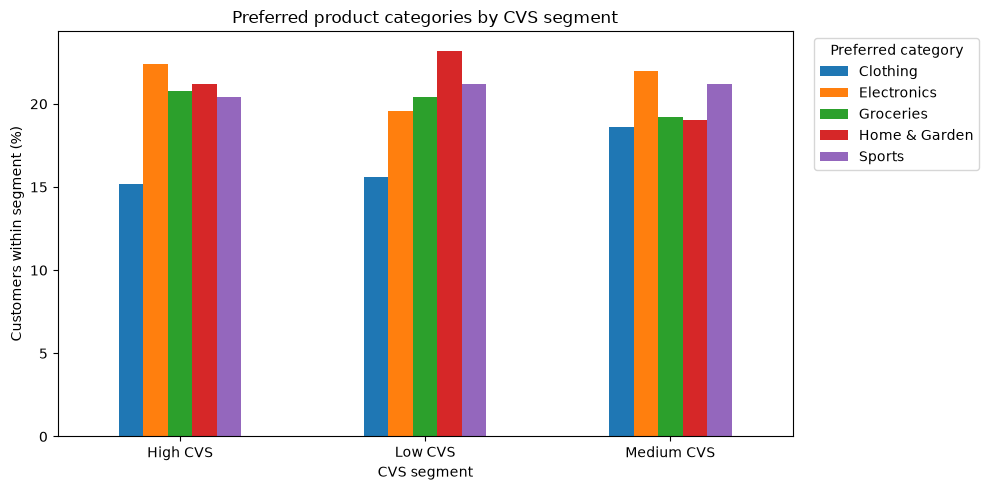

In [238]:
#Shifting the objective to customer retention, using CVS level + preferred product category to propose relevant actions.
preferences = pd.crosstab(
    customer_segmentation_data["CVS_group"],
    customer_segmentation_data["preferred_category"],
    normalize="index"
).mul(100)

preferences.plot(kind="bar", figsize=(10, 5))

plt.title("Preferred product categories by CVS segment")
plt.xlabel("CVS segment")
plt.ylabel("Customers within segment (%)")
plt.xticks(rotation=0)
plt.legend(title="Preferred category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Loyalty indicator


In [239]:
# LOYALTY SCORE
# 50% Purchase frequency
# 50% Membership years

# Defining the columns for loyalty:
loyalty_columns = [
    "membership_years"
]

# Creating a normalized column using the function from customer_scoring.py:
for column in loyalty_columns:
    customer_segmentation_data[column + "_norm"] = cs.normalize(
        customer_segmentation_data[column],
        customer_segmentation_data[column].min(),
        customer_segmentation_data[column].max()
    )

# Viewing the results for the first five customers:
customer_segmentation_data[
    [column + "_norm" for column in loyalty_columns]
].head()


,membership_years_norm
0,22.222222
1,11.111111
2,11.111111
3,88.888889
4,22.222222


In [240]:
# Applying the function from customer_scoring.py to calculate CVS for each customer:
customer_segmentation_data["Loyalty_score"] = cs.calculate_loyalty(
    customer_segmentation_data["purchase_frequency_norm"],
    customer_segmentation_data["membership_years_norm"]
)

# Viewing the results for the first five customers:
display(
    customer_segmentation_data[
        [
            "purchase_frequency_norm",
            "membership_years_norm",
            "Loyalty_score"
        ]
    ].head()
)

,purchase_frequency_norm,membership_years_norm,Loyalty_score
0,46.938776,22.222222,34.580499
1,83.673469,11.111111,47.392290
2,55.102041,11.111111,33.106576
3,8.163265,88.888889,48.526077
4,48.979592,22.222222,35.600907


In [241]:
#checking the Loyalty score for errors before creating customers segments
customer_segmentation_data["Loyalty_score"].isna().sum()

np.int64(0)

In [242]:
customer_segmentation_data["Loyalty_score"].describe()

count    1000.000000
mean       50.946145
std        22.248989
min         0.000000
25%        35.005669
50%        51.190476
75%        66.638322
max       100.000000
Name: Loyalty_score, dtype: float64

In [243]:
# Creating the segments using the function from customer_scoring.py:

# Assigning a Loyalty segment to each customer:

customer_segmentation_data["Loyalty_group"] = [
    cs.assign_segment_loyalty(ls)
    for ls in customer_segmentation_data["Loyalty_score"]
]  # List comprehension

# Viewing the results:
customer_segmentation_data.head()

,id,age,gender,income,spending_score,membership_years,purchase_frequency,preferred_category,last_purchase_amount,age_group,...,membership_group,purchase_frequency_group,purchase_frequency_norm,spending_score_norm,last_purchase_amount_norm,CVS,CVS_group,membership_years_norm,Loyalty_score,Loyalty_group
0,1,38,Female,99342,90,3,24,Groceries,113.53,36-45,...,Developping member,Lower-middle frequency,46.938776,89.898990,10.424121,49.087296,Medium CVS,22.222222,34.580499,Low loyalty
1,2,21,Female,78852,60,2,42,Sports,41.93,18-25,...,Developping member,High frequency,83.673469,59.595960,3.186973,48.818801,Medium CVS,11.111111,47.392290,Medium loyalty
2,3,60,Female,126573,30,2,28,Clothing,424.36,46-60,...,Developping member,Upper-middle frequency,55.102041,29.292929,41.842036,42.079002,Medium CVS,11.111111,33.106576,Low loyalty
3,4,40,Other,47099,74,9,5,Home & Garden,991.93,36-45,...,Longterm member,Low frequency,8.163265,73.737374,99.210585,60.370408,Medium CVS,88.888889,48.526077,Medium loyalty
4,5,65,Female,140621,21,3,25,Electronics,347.08,61+,...,Developping member,Lower-middle frequency,48.979592,20.202020,34.030768,34.404127,Low CVS,22.222222,35.600907,Medium loyalty


In [244]:
# Examining the characteristics of different loyalty groups
loyalty_profile = customer_segmentation_data.groupby(
    "Loyalty_group"
)[
    ["age", "income", "spending_score",
     "purchase_frequency", "membership_years",
     "last_purchase_amount", "CVS"]
].mean()

display(loyalty_profile.round(2))

,age,income,spending_score,purchase_frequency,membership_years,last_purchase_amount,CVS
Loyalty_group,,,,,,,
High loyalty,43.05,88524.36,53.07,39.04,8.38,510.28,60.25
Low loyalty,43.70,90234.59,51.77,13.09,2.76,496.10,41.68
Medium loyalty,44.19,87622.13,48.95,27.13,5.37,481.51,49.79


In [245]:
#Age range distribution per loaylty segment , no huge difference here
age_loyalty = pd.crosstab(
 customer_segmentation_data["Loyalty_group"],
    customer_segmentation_data["age_group"],
    normalize="index"
) * 100

display(age_loyalty.round(2))

age_group,18-25,26-35,36-45,46-60,61+
Loyalty_group,,,,,
High loyalty,15.2,20.8,17.6,32.0,14.4
Low loyalty,15.2,21.6,15.6,28.0,19.6
Medium loyalty,13.6,18.4,19.0,30.6,18.4


In [246]:
# comparison between the loyalty level and preffered category
category_loyalty = pd.crosstab(
    customer_segmentation_data["preferred_category"],
    customer_segmentation_data["Loyalty_group"],
    normalize="columns"
) * 100

display(
    category_loyalty.style
    .format("{:.2f}%")
    .highlight_max(axis=0, color="lightgreen")
)

Loyalty_group,High loyalty,Low loyalty,Medium loyalty
preferred_category,,,
Clothing,16.40%,18.40%,16.60%
Electronics,24.80%,21.20%,20.00%
Groceries,19.60%,20.40%,19.80%
Home & Garden,16.80%,20.40%,22.60%
Sports,22.40%,19.60%,21.00%


In [247]:
# Examining the pruchasing patterns between the preffered categories
category_sales = customer_segmentation_data.groupby(
    "preferred_category"
)["last_purchase_amount"].agg(["count", "mean", "sum"])

display(category_sales.round(2))

,count,mean,sum
preferred_category,,,
Clothing,170,489.65,83240.23
Electronics,215,496.63,106775.94
Groceries,199,487.28,96968.60
Home & Garden,206,505.60,104153.73
Sports,210,481.95,101210.17
